# 03 - Exploratory Data Analysis (EDA)

## Project: SmartCommerce - Brazilian E-Commerce Analytics

### Objective
Explore the cleaned e-commerce datasets to identify:
- Order patterns
- Product performance
- Customer behavior
- Sales trends
- Customer satisfaction

In [1]:
# Step 1: Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Visualization style
sns.set_style("whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
# Step 2: Load cleaned datasets

orders = pd.read_csv("../data/processed/orders_cleaned.csv")

products = pd.read_csv("../data/processed/products_cleaned.csv")

reviews = pd.read_csv("../data/processed/reviews_cleaned.csv")

print("All datasets loaded successfully!")

# Display dataset shapes
print("\nORDERS SHAPE:", orders.shape)
print("PRODUCTS SHAPE:", products.shape)
print("REVIEWS SHAPE:", reviews.shape)

All datasets loaded successfully!

ORDERS SHAPE: (99441, 12)
PRODUCTS SHAPE: (32951, 16)
REVIEWS SHAPE: (99224, 9)


In [3]:
# Step 3: Display first 5 rows of each dataset

print("===== ORDERS DATA =====")
display(orders.head())

print("\n===== PRODUCTS DATA =====")
display(products.head())

print("\n===== REVIEWS DATA =====")
display(reviews.head())

===== ORDERS DATA =====


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,delivery_date_issue,order_approved_at_missing,order_delivered_carrier_date_missing,order_delivered_customer_date_missing
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,False,0,0,0
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,False,0,0,0
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,False,0,0,0
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,False,0,0,0
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,False,0,0,0



===== PRODUCTS DATA =====


,product_id,product_category_name,product_name_lenght,product_description_lenght,product_photos_qty,product_weight_g,product_length_cm,product_height_cm,product_width_cm,product_name_lenght_missing,product_description_lenght_missing,product_photos_qty_missing,product_weight_g_missing,product_length_cm_missing,product_height_cm_missing,product_width_cm_missing
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,40.0,287.0,1.0,225.0,16.0,10.0,14.0,0,0,0,0,0,0,0
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,44.0,276.0,1.0,1000.0,30.0,18.0,20.0,0,0,0,0,0,0,0
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,46.0,250.0,1.0,154.0,18.0,9.0,15.0,0,0,0,0,0,0,0
3,cef67bcfe19066a932b7673e239eb23d,bebes,27.0,261.0,1.0,371.0,26.0,4.0,26.0,0,0,0,0,0,0,0
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,37.0,402.0,4.0,625.0,20.0,17.0,13.0,0,0,0,0,0,0,0



===== REVIEWS DATA =====


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp,review_comment_title_missing,review_comment_message_missing
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59,1,1
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13,1,1
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24,1,1
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06,1,0
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53,1,0


In [4]:
# Step 4: Check all column names

print("ORDERS COLUMNS:")
print(orders.columns.tolist())

print("\nPRODUCTS COLUMNS:")
print(products.columns.tolist())

print("\nREVIEWS COLUMNS:")
print(reviews.columns.tolist())

ORDERS COLUMNS:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_date_issue', 'order_approved_at_missing', 'order_delivered_carrier_date_missing', 'order_delivered_customer_date_missing']

PRODUCTS COLUMNS:
['product_id', 'product_category_name', 'product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'product_weight_g', 'product_length_cm', 'product_height_cm', 'product_width_cm', 'product_name_lenght_missing', 'product_description_lenght_missing', 'product_photos_qty_missing', 'product_weight_g_missing', 'product_length_cm_missing', 'product_height_cm_missing', 'product_width_cm_missing']

REVIEWS COLUMNS:
['review_id', 'order_id', 'review_score', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp', 'review_comment_title_missing', 'review_comment_message_missing']


In [5]:

# Step 4: Check missing values and duplicates

datasets = {
    "ORDERS": orders,
    "PRODUCTS": products,
    "REVIEWS": reviews
}

for name, df in datasets.items():
    print(f"\n===== {name} =====")

    print("Shape:", df.shape)

    print("Duplicate rows:", df.duplicated().sum())

    print("\nMissing values:")
    print(df.isnull().sum())

    print("Total missing:", df.isnull().sum().sum())



===== ORDERS =====
Shape: (99441, 12)
Duplicate rows: 0

Missing values:
order_id                                    0
customer_id                                 0
order_status                                0
order_purchase_timestamp                    0
order_approved_at                         160
order_delivered_carrier_date             1783
order_delivered_customer_date            2965
order_estimated_delivery_date               0
delivery_date_issue                         0
order_approved_at_missing                   0
order_delivered_carrier_date_missing        0
order_delivered_customer_date_missing       0
dtype: int64
Total missing: 4908

===== PRODUCTS =====
Shape: (32951, 16)
Duplicate rows: 0

Missing values:
product_id                              0
product_category_name                   0
product_name_lenght                   610
product_description_lenght            610
product_photos_qty                    610
product_weight_g                        0
product_lengt

In [6]:

# Step 5: Missing Values Analysis

for name, df in datasets.items():
    print(f"\n===== {name} MISSING VALUES =====")

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    missing_df = pd.DataFrame({
        "Missing Count": missing,
        "Missing Percentage": (
            missing / len(df) * 100
        ).round(2)
    })

    print(missing_df.sort_values(
        by="Missing Percentage",
        ascending=False
    ))



===== ORDERS MISSING VALUES =====
                               Missing Count  Missing Percentage
order_delivered_customer_date           2965                2.98
order_delivered_carrier_date            1783                1.79
order_approved_at                        160                0.16

===== PRODUCTS MISSING VALUES =====
                            Missing Count  Missing Percentage
product_name_lenght                   610                1.85
product_description_lenght            610                1.85
product_photos_qty                    610                1.85

===== REVIEWS MISSING VALUES =====
                        Missing Count  Missing Percentage
review_comment_title            87656               88.34
review_comment_message          58247               58.70


ORDER STATUS COUNTS
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

ORDER STATUS PERCENTAGES
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


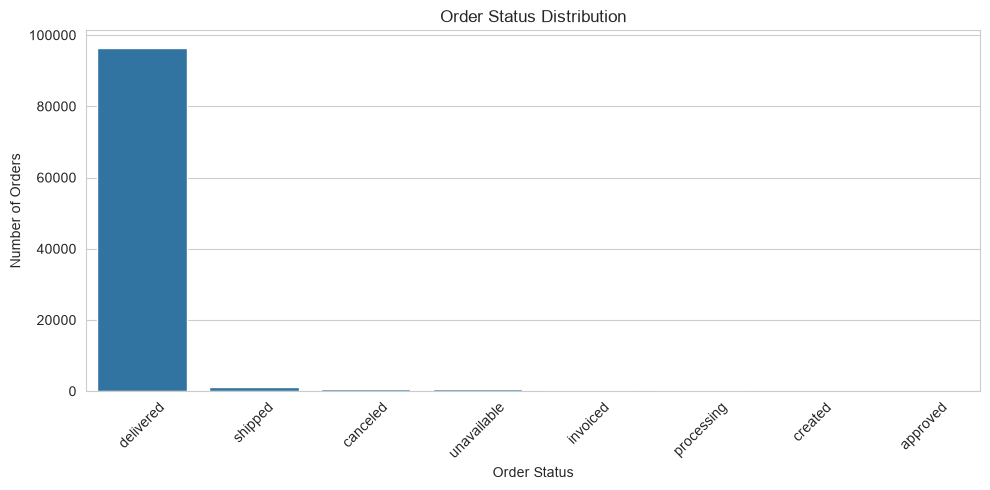

In [7]:

# Step 6: Order Status Distribution

status_counts = orders["order_status"].value_counts()

print("ORDER STATUS COUNTS")
print(status_counts)

print("\nORDER STATUS PERCENTAGES")
print((orders["order_status"].value_counts(normalize=True) * 100).round(2))

# Visualize order status
plt.figure(figsize=(10, 5))

sns.countplot(
    data=orders,
    x="order_status",
    order=orders["order_status"].value_counts().index
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()


In [8]:
print(status_counts)
print((status_counts / len(orders) * 100).round(2))

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64
order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: count, dtype: float64


MONTHLY ORDER COUNTS
order_purchase_timestamp
2016-09-01       4
2016-10-01     324
2016-11-01       0
2016-12-01       1
2017-01-01     800
2017-02-01    1780
2017-03-01    2682
2017-04-01    2404
2017-05-01    3700
2017-06-01    3245
2017-07-01    4026
2017-08-01    4331
2017-09-01    4285
2017-10-01    4631
2017-11-01    7544
2017-12-01    5673
2018-01-01    7269
2018-02-01    6728
2018-03-01    7211
2018-04-01    6939
2018-05-01    6873
2018-06-01    6167
2018-07-01    6292
2018-08-01    6512
2018-09-01      16
2018-10-01       4
Freq: MS, Name: order_id, dtype: int64

Highest order month:
2017-11-01 00:00:00 7544

Lowest order month:
2016-11-01 00:00:00 0


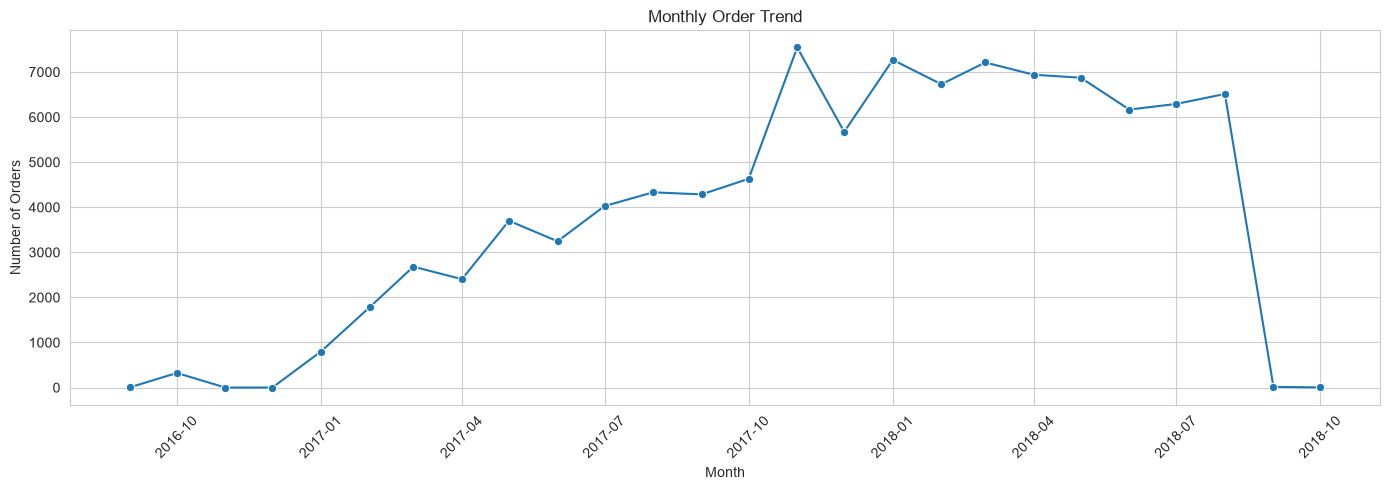

In [9]:

# Step 7: Monthly Order Trend

# Convert timestamp to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Group orders by month
monthly_orders = (
    orders.dropna(subset=["order_purchase_timestamp"])
    .set_index("order_purchase_timestamp")
    .resample("MS")["order_id"]
    .count()
)

print("MONTHLY ORDER COUNTS")
print(monthly_orders)

# Highest and lowest order months
print("\nHighest order month:")
print(monthly_orders.idxmax(), monthly_orders.max())

print("\nLowest order month:")
print(monthly_orders.idxmin(), monthly_orders.min())

# Visualization
plt.figure(figsize=(14, 5))

sns.lineplot(
    x=monthly_orders.index,
    y=monthly_orders.values,
    marker="o"
)

plt.title("Monthly Order Trend")
plt.xlabel("Month")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()


In [10]:

print("Highest month:")
print(monthly_orders.idxmax(), monthly_orders.max())

print("\nLowest month (including zero):")
print(monthly_orders.idxmin(), monthly_orders.min())

print("\nLowest month (excluding zero):")
print(monthly_orders[monthly_orders > 0].idxmin(),
      monthly_orders[monthly_orders > 0].min())


Highest month:
2017-11-01 00:00:00 7544

Lowest month (including zero):
2016-11-01 00:00:00 0

Lowest month (excluding zero):
2016-12-01 00:00:00 1


TOP 10 PRODUCT CATEGORIES
product_category_name
cama_mesa_banho           3029
esporte_lazer             2867
moveis_decoracao          2657
beleza_saude              2444
utilidades_domesticas     2335
automotivo                1900
informatica_acessorios    1639
brinquedos                1411
relogios_presentes        1329
telefonia                 1134
Name: count, dtype: int64

BOTTOM 10 PRODUCT CATEGORIES
product_category_name
fraldas_higiene                                  12
la_cuisine                                       10
portateis_cozinha_e_preparadores_de_alimentos    10
moveis_colchao_e_estofado                        10
tablets_impressao_imagem                          9
fashion_roupa_infanto_juvenil                     5
casa_conforto_2                                   5
pc_gamer                                          3
seguros_e_servicos                                2
cds_dvds_musicais                                 1
Name: count, dtype: int64


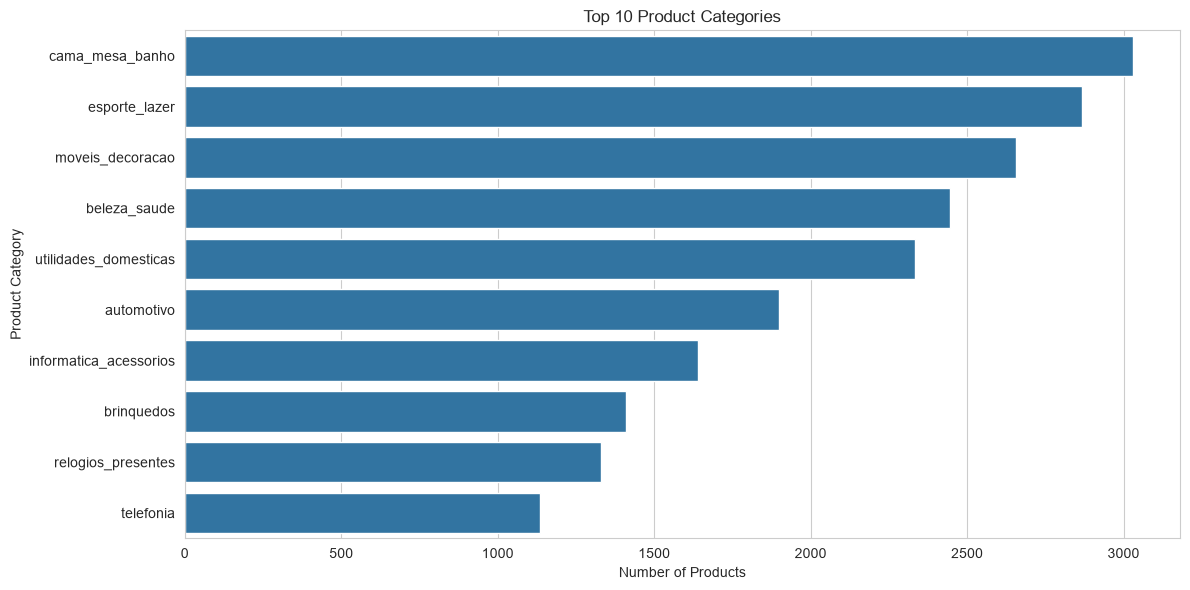


Total unique categories: 74


In [11]:

# Step 8: Product Category Analysis

# Count products in each category
category_counts = (
    products["product_category_name"]
    .value_counts()
)

print("TOP 10 PRODUCT CATEGORIES")
print(category_counts.head(10))

print("\nBOTTOM 10 PRODUCT CATEGORIES")
print(category_counts.tail(10))

# Visualize top 10 categories
plt.figure(figsize=(12, 6))

sns.barplot(
    x=category_counts.head(10).values,
    y=category_counts.head(10).index
)

plt.title("Top 10 Product Categories")
plt.xlabel("Number of Products")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

# Total categories
print("\nTotal unique categories:", 
      products["product_category_name"].nunique())


REVIEW SCORE DISTRIBUTION
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64

REVIEW SCORE PERCENTAGES
review_score
1    11.51
2     3.18
3     8.24
4    19.29
5    57.78
Name: proportion, dtype: float64

Average Review Score: 4.09
Median Review Score: 5.0


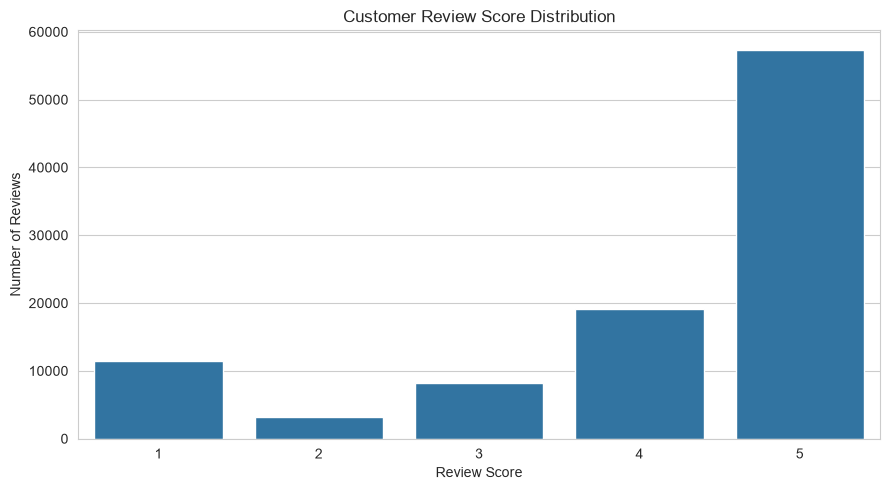

In [12]:

# Step 9: Customer Review Score Analysis

# Count review scores
review_counts = reviews["review_score"].value_counts().sort_index()

print("REVIEW SCORE DISTRIBUTION")
print(review_counts)

print("\nREVIEW SCORE PERCENTAGES")
print(
    (reviews["review_score"].value_counts(normalize=True)
     .sort_index() * 100).round(2)
)

# Average review score
average_rating = reviews["review_score"].mean()
median_rating = reviews["review_score"].median()

print("\nAverage Review Score:", round(average_rating, 2))
print("Median Review Score:", median_rating)

# Visualization
plt.figure(figsize=(9, 5))

sns.countplot(
    data=reviews,
    x="review_score",
    order=sorted(reviews["review_score"].dropna().unique())
)

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")

plt.tight_layout()
plt.show()


DELIVERY TIME STATISTICS
count    96470.00
mean        12.56
std          9.55
min          0.53
25%          6.77
50%         10.22
75%         15.72
max        209.63
Name: delivery_days, dtype: float64

Average delivery time: 12.56 days
Median delivery time: 10.22 days


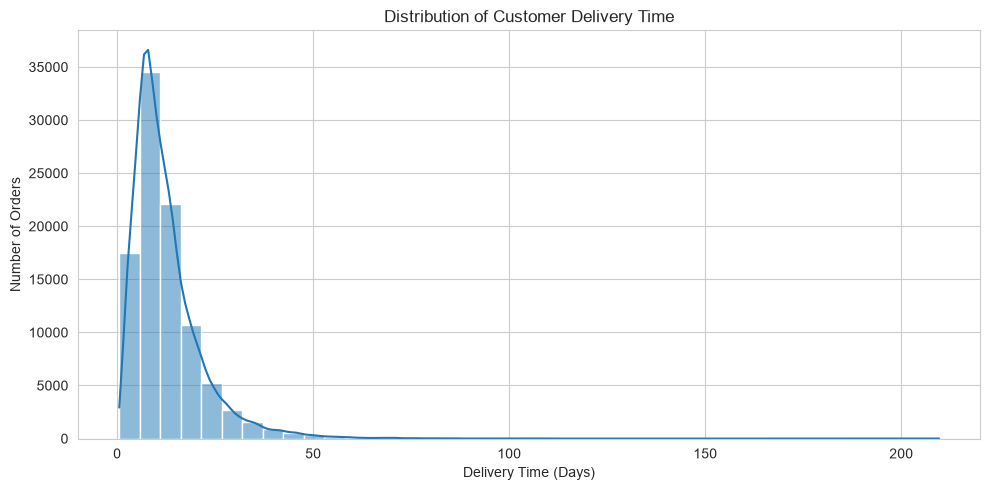

In [13]:
# Step 10: Delivery Time Analysis

# Convert date columns to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"], errors="coerce"
)

orders["order_delivered_customer_date"] = pd.to_datetime(
    orders["order_delivered_customer_date"], errors="coerce"
)

# Consider only delivered orders with valid delivery dates
delivered_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"].notna()) &
    (orders["order_delivered_customer_date"].notna())
].copy()

# Calculate delivery time in days
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"] -
    delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Display statistics
print("DELIVERY TIME STATISTICS")
print(delivered_orders["delivery_days"].describe().round(2))

print("\nAverage delivery time:",
      round(delivered_orders["delivery_days"].mean(), 2), "days")

print("Median delivery time:",
      round(delivered_orders["delivery_days"].median(), 2), "days")

# Plot delivery time distribution
plt.figure(figsize=(10, 5))
sns.histplot(delivered_orders["delivery_days"], bins=40, kde=True)
plt.title("Distribution of Customer Delivery Time")
plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

In [14]:
# Step 11: Inspect the 10 Longest Deliveries

longest_deliveries = delivered_orders[
    [
        "order_id",
        "order_status",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "delivery_days"
    ]
].sort_values(
    by="delivery_days",
    ascending=False
).head(10)

print(longest_deliveries.to_string(index=False))

                        order_id order_status order_purchase_timestamp order_delivered_customer_date  delivery_days
ca07593549f1816d26a572e06dc1eab6    delivered      2017-02-21 23:31:27           2017-09-19 14:36:39     209.628611
1b3190b2dfa9d789e1f14c05b647a14a    delivered      2018-02-23 14:57:35           2018-09-19 23:24:07     208.351759
440d0d17af552815d15a9e41abe49359    delivered      2017-03-07 23:59:51           2017-09-19 15:12:50     195.634016
2fb597c2f772eca01b1f5c561bf6cc7b    delivered      2017-03-08 18:09:02           2017-09-19 14:33:17     194.850174
285ab9426d6982034523a855f55a885e    delivered      2017-03-08 22:47:40           2017-09-19 14:00:04     194.633611
0f4519c5f1c541ddec9f21b3bddd533a    delivered      2017-03-09 13:26:57           2017-09-19 14:38:21     194.049583
47b40429ed8cce3aee9199792275433f    delivered      2018-01-03 09:44:01           2018-07-13 20:51:31     191.463542
2fe324febf907e3ea3f2aa9650869fa5    delivered      2017-03-13 20:17:10  

In [15]:
# Step 12: Count Extremely Long Deliveries

thresholds = [15, 30, 60, 90, 120, 180]

total_orders = len(delivered_orders)

for days in thresholds:
    count = (delivered_orders["delivery_days"] > days).sum()
    percentage = (count / total_orders) * 100

    print(
        f"Orders taking more than {days} days: "
        f"{count:,} ({percentage:.2f}%)"
    )

# Check available date columns
print("\nORDER DATASET COLUMNS:")
print(orders.columns.tolist())

Orders taking more than 15 days: 26,377 (27.34%)
Orders taking more than 30 days: 4,550 (4.72%)
Orders taking more than 60 days: 306 (0.32%)
Orders taking more than 90 days: 77 (0.08%)
Orders taking more than 120 days: 43 (0.04%)
Orders taking more than 180 days: 14 (0.01%)

ORDER DATASET COLUMNS:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'delivery_date_issue', 'order_approved_at_missing', 'order_delivered_carrier_date_missing', 'order_delivered_customer_date_missing']


In [17]:
# Step 13 (Corrected): Delivery Performance

# Compare calendar dates, not exact timestamps
actual_date = delivered_orders[
    "order_delivered_customer_date"
].dt.normalize()

estimated_date = delivered_orders[
    "order_estimated_delivery_date"
].dt.normalize()

# Positive = late, zero = on time, negative = early
delivered_orders["delivery_difference_days"] = (
    actual_date - estimated_date
).dt.days

delivered_orders["delivery_performance"] = np.where(
    delivered_orders["delivery_difference_days"] > 0,
    "Late",
    "On Time or Early"
)

print("DELIVERY PERFORMANCE")
print(delivered_orders["delivery_performance"].value_counts())

print("\nDELIVERY PERFORMANCE PERCENTAGES")
print(
    (delivered_orders["delivery_performance"]
     .value_counts(normalize=True) * 100).round(2)
)

print("\nAVERAGE DAYS DIFFERENCE:")
print(round(delivered_orders["delivery_difference_days"].mean(), 2))

DELIVERY PERFORMANCE
delivery_performance
On Time or Early    89936
Late                 6534
Name: count, dtype: int64

DELIVERY PERFORMANCE PERCENTAGES
delivery_performance
On Time or Early    93.23
Late                 6.77
Name: proportion, dtype: float64

AVERAGE DAYS DIFFERENCE:
-11.88


In [18]:
# Step 14: Check Review Records Before Merging

print("Total review records:", len(reviews))

print("Unique reviewed orders:", reviews["order_id"].nunique())

print(
    "Duplicate order IDs in reviews:",
    reviews["order_id"].duplicated().sum()
)

print("\nReview score counts:")
print(reviews["review_score"].value_counts().sort_index())

Total review records: 99224
Unique reviewed orders: 98673
Duplicate order IDs in reviews: 551

Review score counts:
review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: count, dtype: int64


In [19]:
# Step 15: Inspect Orders with Multiple Reviews

duplicate_reviews = reviews[
    reviews["order_id"].duplicated(keep=False)
].sort_values("order_id")

print("Total records belonging to duplicate order IDs:",
      len(duplicate_reviews))

print("\nFirst 15 duplicate review records:")
print(
    duplicate_reviews[
        ["order_id", "review_id", "review_score",
         "review_comment_title", "review_comment_message"]
    ].head(15).to_string(index=False)
)

print("\nNumber of orders with multiple reviews:",
      duplicate_reviews["order_id"].nunique())

Total records belonging to duplicate order IDs: 1098

First 15 duplicate review records:
                        order_id                        review_id  review_score review_comment_title                                                                                                                                              review_comment_message
0035246a40f520710769010f752e7507 2a74b0559eb58fc1ff842ecc999594cb             5                  NaN                                         Estou acostumada a comprar produtos pelo baratheon. Super confiável, transparência, qualidade e agilidade. Super recomendo.
0035246a40f520710769010f752e7507 89a02c45c340aeeb1354a24e7d4b2c1e             5                  NaN                                                                                                                                                                 NaN
013056cfe49763c6f66bda03396c5ee3 ab30810c29da5da8045216f0f62652a2             5                  NaN                

In [20]:
# Step 16: Calculate Average Review Score Per Order

# Aggregate multiple reviews into one average score per order
reviews_per_order = (
    reviews.groupby("order_id")
    .agg(
        average_review_score=("review_score", "mean"),
        review_count=("review_score", "count")
    )
    .reset_index()
)

print("Unique orders with reviews:", len(reviews_per_order))

# Merge with delivery performance data
delivery_reviews = delivered_orders.merge(
    reviews_per_order,
    on="order_id",
    how="inner",
    validate="one_to_one"
)

print("\nMERGED DATASET SHAPE:")
print(delivery_reviews.shape)

print("\nDELIVERY PERFORMANCE COUNTS:")
print(delivery_reviews["delivery_performance"].value_counts())

print("\nAVERAGE REVIEW SCORE:")
print(round(delivery_reviews["average_review_score"].mean(), 2))

print("\nORDERS WITHOUT MATCHING REVIEWS:")
print(len(delivered_orders) - len(delivery_reviews))

Unique orders with reviews: 98673

MERGED DATASET SHAPE:
(95824, 17)

DELIVERY PERFORMANCE COUNTS:
delivery_performance
On Time or Early    89443
Late                 6381
Name: count, dtype: int64

AVERAGE REVIEW SCORE:
4.16

ORDERS WITHOUT MATCHING REVIEWS:
646


CUSTOMER RATING COMPARISON
                      total_orders  average_rating  median_rating
delivery_performance                                             
Late                          6381            2.27            1.0
On Time or Early             89443            4.29            5.0

RATING DIFFERENCE:
2.02


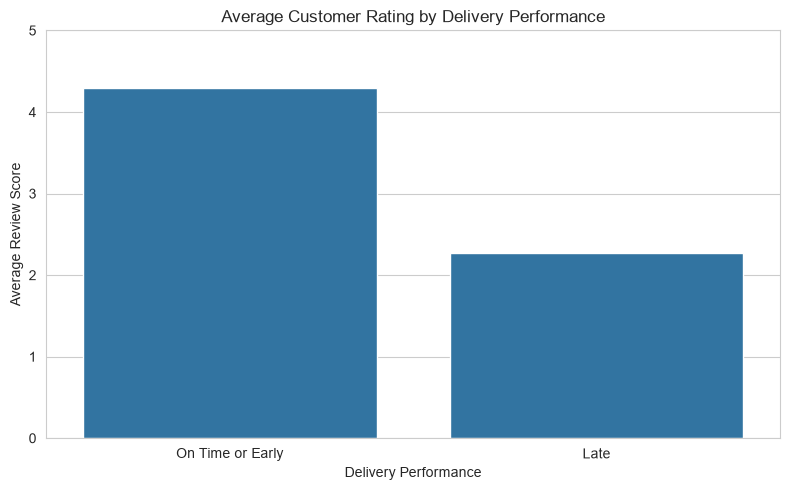

In [21]:
# Step 17: Compare Customer Ratings by Delivery Performance

rating_comparison = (
    delivery_reviews.groupby("delivery_performance")
    .agg(
        total_orders=("order_id", "count"),
        average_rating=("average_review_score", "mean"),
        median_rating=("average_review_score", "median")
    )
    .round(2)
)

print("CUSTOMER RATING COMPARISON")
print(rating_comparison)

# Calculate rating difference
on_time_rating = rating_comparison.loc[
    "On Time or Early", "average_rating"
]

late_rating = rating_comparison.loc[
    "Late", "average_rating"
]

print("\nRATING DIFFERENCE:")
print(round(on_time_rating - late_rating, 2))

# Visualize the comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=delivery_reviews,
    x="delivery_performance",
    y="average_review_score",
    errorbar=None
)

plt.title("Average Customer Rating by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

In [22]:
# Step 18: Low-Rating Percentage by Delivery Performance

delivery_reviews["low_rating"] = (
    delivery_reviews["average_review_score"] <= 2
)

low_rating_analysis = (
    delivery_reviews.groupby("delivery_performance")
    .agg(
        total_orders=("order_id", "count"),
        low_rating_orders=("low_rating", "sum")
    )
)

low_rating_analysis["low_rating_percentage"] = (
    low_rating_analysis["low_rating_orders"] /
    low_rating_analysis["total_orders"] * 100
).round(2)

print("LOW-RATING ANALYSIS")
print(low_rating_analysis)

# Calculate the difference in low-rating percentages
late_low_rating = low_rating_analysis.loc[
    "Late", "low_rating_percentage"
]

ontime_low_rating = low_rating_analysis.loc[
    "On Time or Early", "low_rating_percentage"
]

print("\nDIFFERENCE IN LOW-RATING PERCENTAGE:")
print(round(late_low_rating - ontime_low_rating, 2), "percentage points")

LOW-RATING ANALYSIS
                      total_orders  low_rating_orders  low_rating_percentage
delivery_performance                                                        
Late                          6381               3979                  62.36
On Time or Early             89443               8257                   9.23

DIFFERENCE IN LOW-RATING PERCENTAGE:
53.13 percentage points


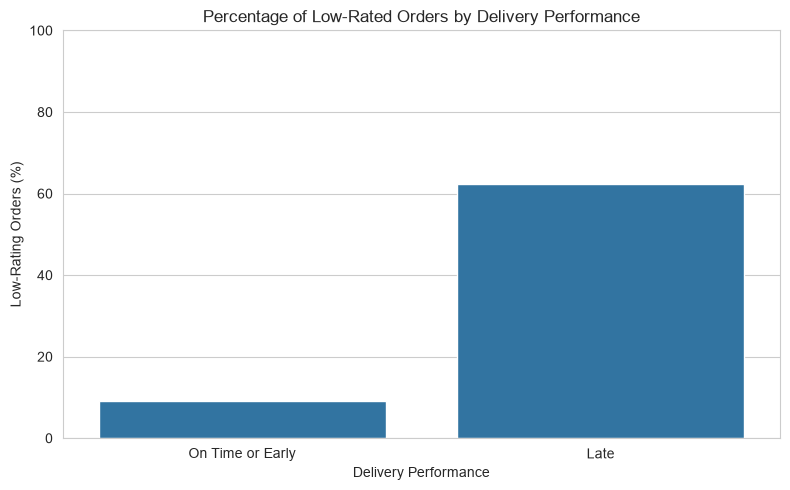

In [23]:
# Step 19: Visualize Low-Rating Percentages

plt.figure(figsize=(8, 5))

sns.barplot(
    data=delivery_reviews,
    x="delivery_performance",
    y="low_rating",
    estimator=lambda x: x.mean() * 100,
    errorbar=None
)

plt.title("Percentage of Low-Rated Orders by Delivery Performance")
plt.xlabel("Delivery Performance")
plt.ylabel("Low-Rating Orders (%)")
plt.ylim(0, 100)

plt.tight_layout()
plt.show()

In [24]:
# Step 20: Load Payments and Order Items

payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")

order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")

print("Payments shape:", payments.shape)
print("Order items shape:", order_items.shape)

print("\nPAYMENTS DATA:")
display(payments.head())

print("\nORDER ITEMS DATA:")
display(order_items.head())

Payments shape: (103886, 5)
Order items shape: (112650, 7)

PAYMENTS DATA:


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45



ORDER ITEMS DATA:


,order_id,order_item_id,product_id,seller_id,shipping_limit_date,price,freight_value
0,00010242fe8c5a6d1ba2dd792cb16214,1,4244733e06e7ecb4970a6e2683c13e61,48436dade18ac8b2bce089ec2a041202,2017-09-19 09:45:35,58.90,13.29
1,00018f77f2f0320c557190d7a144bdd3,1,e5f2d52b802189ee658865ca93d83a8f,dd7ddc04e1b6c2c614352b383efe2d36,2017-05-03 11:05:13,239.90,19.93
2,000229ec398224ef6ca0657da4fc703e,1,c777355d18b72b67abbeef9df44fd0fd,5b51032eddd242adc84c38acab88f23d,2018-01-18 14:48:30,199.00,17.87
3,00024acbcdf0a6daa1e931b038114c75,1,7634da152a4610f1595efa32f14722fc,9d7a1d34a5052409006425275ba1c2b4,2018-08-15 10:10:18,12.99,12.79
4,00042b26cf59d7ce69dfabb4e55b4fd9,1,ac6c3623068f30de03045865e4e10089,df560393f3a51e74553ab94004ba5c87,2017-02-13 13:57:51,199.90,18.14


In [25]:
# Step 21: Payment and Revenue Analysis

# Total payment value for each order
order_payments = (
    payments.groupby("order_id")
    .agg(total_payment=("payment_value", "sum"))
    .reset_index()
)

print("TOTAL PAYMENT STATISTICS")

print("Total payment records:", len(payments))
print("Unique orders with payments:", len(order_payments))

print(
    "Total payment value: R$",
    round(payments["payment_value"].sum(), 2)
)

print(
    "Average payment per order: R$",
    round(order_payments["total_payment"].mean(), 2)
)

print(
    "Median payment per order: R$",
    round(order_payments["total_payment"].median(), 2)
)

print("\nTOP 10 PAYMENT METHODS")
print(payments["payment_type"].value_counts())

TOTAL PAYMENT STATISTICS
Total payment records: 103886
Unique orders with payments: 99440
Total payment value: R$ 16008872.12
Average payment per order: R$ 160.99
Median payment per order: R$ 105.29

TOP 10 PAYMENT METHODS
payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: count, dtype: int64


MONTHLY RECORDED PAYMENTS
order_purchase_timestamp
2016-09-01        252.24
2016-10-01      59090.48
2016-11-01          0.00
2016-12-01         19.62
2017-01-01     138488.04
2017-02-01     291908.01
2017-03-01     449863.60
2017-04-01     417788.03
2017-05-01     592918.82
2017-06-01     511276.38
2017-07-01     592382.92
2017-08-01     674396.32
2017-09-01     727762.45
2017-10-01     779677.88
2017-11-01    1194882.80
2017-12-01     878401.48
2018-01-01    1115004.18
2018-02-01     992463.34
2018-03-01    1159652.12
2018-04-01    1160785.48
2018-05-01    1153982.15
2018-06-01    1023880.50
2018-07-01    1066540.75
2018-08-01    1022425.32
2018-09-01       4439.54
2018-10-01        589.67
Freq: MS, Name: total_payment, dtype: float64

Highest payment month:
2017-11-01 00:00:00 R$ 1194882.8


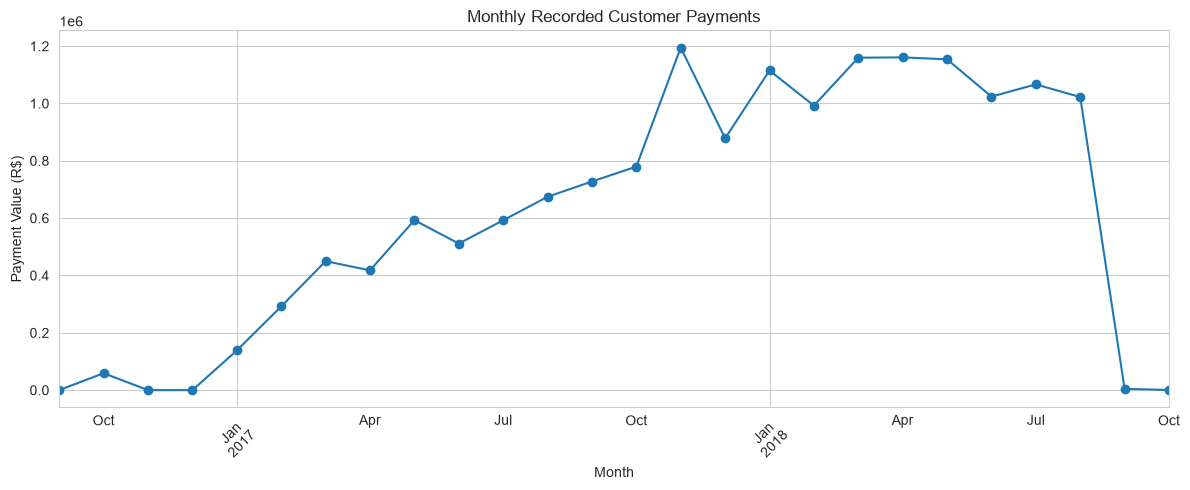

In [26]:
# Step 22: Monthly Payment Trend

# Keep one purchase date and status per order
order_dates = orders[
    ["order_id", "order_purchase_timestamp", "order_status"]
].copy()

# Merge order-level payments with purchase dates
monthly_payments = order_payments.merge(
    order_dates,
    on="order_id",
    how="inner",
    validate="one_to_one"
)

# Convert purchase timestamp
monthly_payments["order_purchase_timestamp"] = pd.to_datetime(
    monthly_payments["order_purchase_timestamp"],
    errors="coerce"
)

# Calculate monthly payment totals
monthly_revenue = (
    monthly_payments
    .dropna(subset=["order_purchase_timestamp"])
    .set_index("order_purchase_timestamp")
    .resample("MS")["total_payment"]
    .sum()
)

print("MONTHLY RECORDED PAYMENTS")
print(monthly_revenue.round(2))

print("\nHighest payment month:")
print(monthly_revenue.idxmax(), "R$", round(monthly_revenue.max(), 2))

# Plot monthly payments
plt.figure(figsize=(12, 5))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Recorded Customer Payments")
plt.xlabel("Month")
plt.ylabel("Payment Value (R$)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [27]:
# Step 23: Product Category Sales Analysis

# Load category translation
category_translation = pd.read_csv(
    "../data/raw/product_category_name_translation.csv"
)

# Merge order items with order status
category_sales = order_items.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left",
    validate="many_to_one"
)

# Keep delivered orders
category_sales = category_sales[
    category_sales["order_status"] == "delivered"
].copy()

# Add product category
category_sales = category_sales.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left",
    validate="many_to_one"
)

# Translate category names into English
category_sales = category_sales.merge(
    category_translation,
    on="product_category_name",
    how="left",
    validate="many_to_one"
)

# Use translated category names where available
category_sales["category"] = (
    category_sales["product_category_name_english"]
    .fillna(category_sales["product_category_name"])
    .fillna("unknown")
)

# Aggregate category sales
category_revenue = (
    category_sales.groupby("category")
    .agg(
        total_items=("order_item_id", "count"),
        total_sales=("price", "sum")
    )
    .sort_values("total_sales", ascending=False)
)

print("TOP 10 PRODUCT CATEGORIES BY SALES VALUE")
print(category_revenue.head(10).round(2))

print("\nTOP CATEGORY:")
print(category_revenue.index[0])
print("Sales value: R$", round(category_revenue.iloc[0]["total_sales"], 2))

print("\nTotal delivered product sales: R$",
      round(category_sales["price"].sum(), 2))

TOP 10 PRODUCT CATEGORIES BY SALES VALUE
                       total_items  total_sales
category                                       
health_beauty                 9465   1233131.72
watches_gifts                 5859   1166176.98
bed_bath_table               10953   1023434.76
sports_leisure                8431    954852.55
computers_accessories         7644    888724.61
furniture_decor               8160    711927.69
housewares                    6795    615628.69
cool_stuff                    3718    610204.10
auto                          4140    578966.65
toys                          4030    471286.48

TOP CATEGORY:
health_beauty
Sales value: R$ 1233131.72

Total delivered product sales: R$ 13221498.11


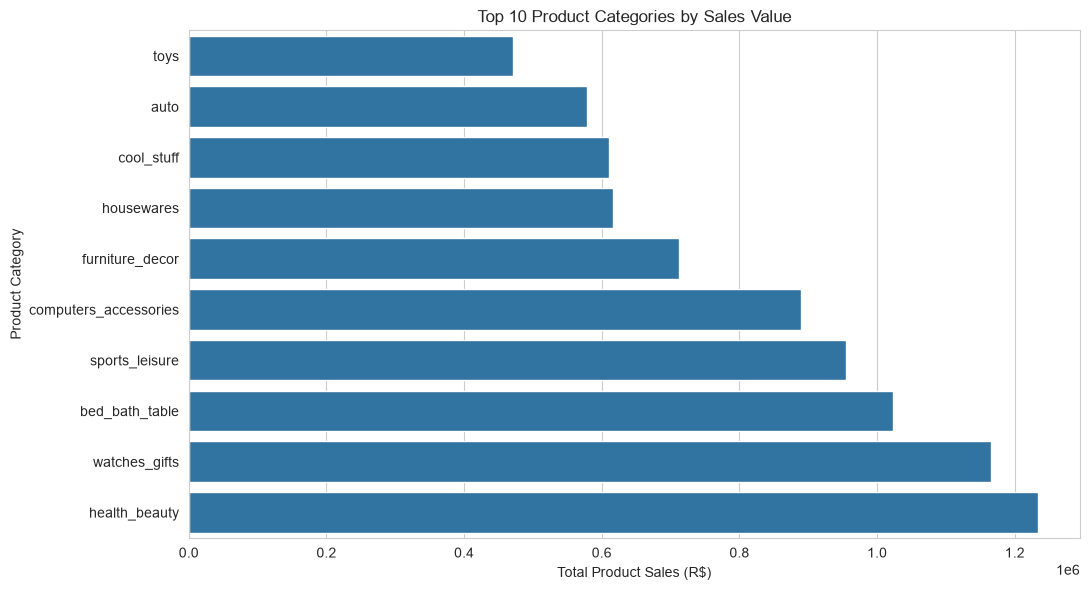

In [28]:
# Step 24: Top 10 Categories by Sales Value

top_categories = category_revenue.head(10).sort_values(
    "total_sales",
    ascending=True
)

plt.figure(figsize=(11, 6))

sns.barplot(
    x=top_categories["total_sales"],
    y=top_categories.index
)

plt.title("Top 10 Product Categories by Sales Value")
plt.xlabel("Total Product Sales (R$)")
plt.ylabel("Product Category")

plt.tight_layout()
plt.show()

In [29]:
# Step 25: Payment Method Analysis

payment_method_analysis = (
    payments.groupby("payment_type")
    .agg(
        transactions=("payment_type", "count"),
        total_payment=("payment_value", "sum")
    )
)

payment_method_analysis["transaction_percentage"] = (
    payment_method_analysis["transactions"] /
    payment_method_analysis["transactions"].sum() * 100
).round(2)

payment_method_analysis["payment_value_percentage"] = (
    payment_method_analysis["total_payment"] /
    payment_method_analysis["total_payment"].sum() * 100
).round(2)

payment_method_analysis = payment_method_analysis.sort_values(
    "total_payment", ascending=False
)

print("PAYMENT METHOD ANALYSIS")
print(payment_method_analysis.round(2))

PAYMENT METHOD ANALYSIS
              transactions  total_payment  transaction_percentage  \
payment_type                                                        
credit_card          76795    12542084.19                   73.92   
boleto               19784     2869361.27                   19.04   
voucher               5775      379436.87                    5.56   
debit_card            1529      217989.79                    1.47   
not_defined              3           0.00                    0.00   

              payment_value_percentage  
payment_type                            
credit_card                      78.34  
boleto                           17.92  
voucher                           2.37  
debit_card                        1.36  
not_defined                       0.00  


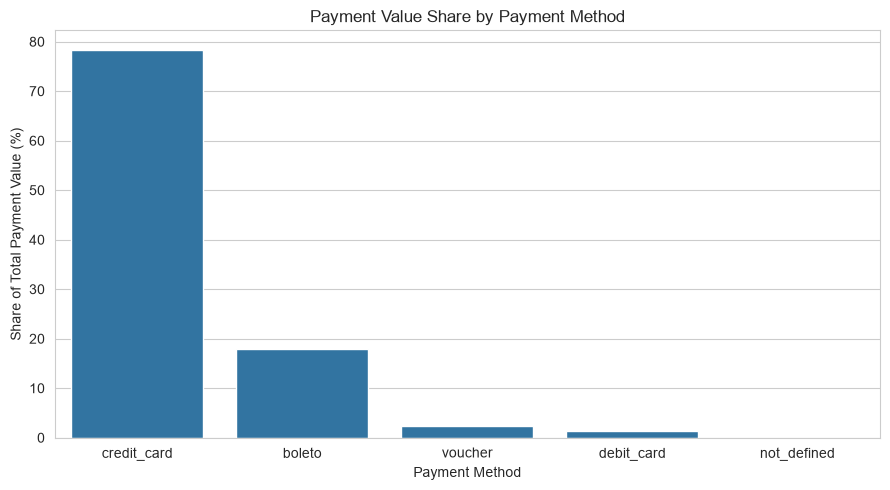

In [30]:
# Step 26: Payment Method Visualization

plt.figure(figsize=(9, 5))

sns.barplot(
    data=payment_method_analysis.reset_index(),
    x="payment_type",
    y="payment_value_percentage"
)

plt.title("Payment Value Share by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Share of Total Payment Value (%)")

plt.tight_layout()
plt.show()

In [31]:
# Step 27: Customer Lifetime Spending Analysis

# Load customer dataset
customers = pd.read_csv(
    "../data/raw/olist_customers_dataset.csv"
)

# Keep delivered orders only
delivered_order_data = orders[
    orders["order_status"] == "delivered"
][["order_id", "customer_id"]].copy()

# Attach unique customer identifiers
customer_orders = delivered_order_data.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="one_to_one"
)

# Attach order-level payments
customer_orders = customer_orders.merge(
    order_payments,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Calculate spending per unique customer
customer_spending = (
    customer_orders.groupby("customer_unique_id")
    .agg(
        total_orders=("order_id", "nunique"),
        lifetime_spending=("total_payment", "sum")
    )
    .reset_index()
)

print("CUSTOMER SPENDING ANALYSIS")
print("Unique customers:", len(customer_spending))
print("Total delivered orders:", customer_orders["order_id"].nunique())

print("\nLIFETIME SPENDING STATISTICS")
print(customer_spending["lifetime_spending"].describe().round(2))

print("\nTOP 10 CUSTOMERS BY LIFETIME SPENDING")
print(
    customer_spending.sort_values(
        "lifetime_spending",
        ascending=False
    ).head(10).round(2).to_string(index=False)
)

CUSTOMER SPENDING ANALYSIS
Unique customers: 93358
Total delivered orders: 96478

LIFETIME SPENDING STATISTICS
count    93358.00
mean       165.20
std        226.31
min          0.00
25%         63.05
50%        107.78
75%        182.56
max      13664.08
Name: lifetime_spending, dtype: float64

TOP 10 CUSTOMERS BY LIFETIME SPENDING
              customer_unique_id  total_orders  lifetime_spending
0a0a92112bd4c708ca5fde585afaa872             1           13664.08
da122df9eeddfedc1dc1f5349a1a690c             2            7571.63
763c8b1c9c68a0229c42c9fc6f662b93             1            7274.88
dc4802a71eae9be1dd28f5d788ceb526             1            6929.31
459bef486812aa25204be022145caa62             1            6922.21
ff4159b92c40ebe40454e3e6a7c35ed6             1            6726.66
4007669dec559734d6f53e029e360987             1            6081.54
eebb5dda148d3893cdaf5b5ca3040ccb             1            4764.34
48e1ac109decbb87765a3eade6854098             1            4681.78
c8460e

CUSTOMER PURCHASE FREQUENCY
Total unique customers: 93358
One-time customers: 90557
Repeat customers: 2801

REPEAT CUSTOMER PERCENTAGE: 3.0 %

ORDERS PER CUSTOMER DISTRIBUTION
order_count
1     90557
2      2573
3       181
4        28
5         9
6         5
7         3
9         1
15        1
Name: count, dtype: int64


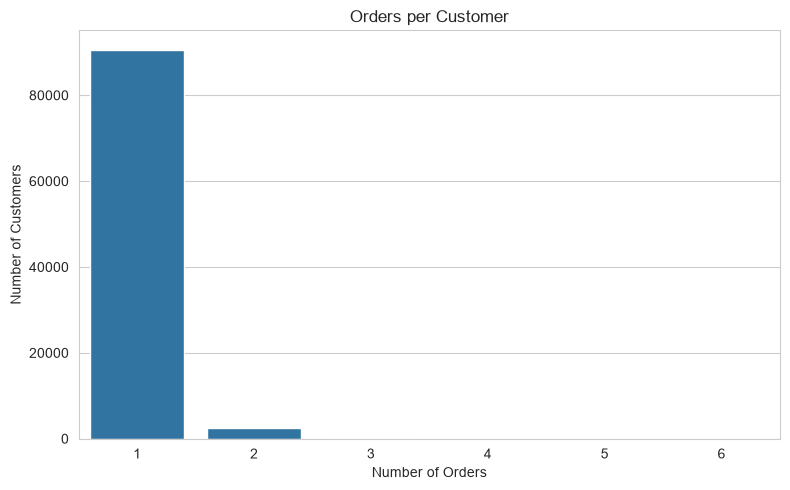

In [32]:
# Step 28: Repeat Customer Analysis

# Count orders per unique customer
customer_order_frequency = (
    customer_orders.groupby("customer_unique_id")
    .agg(order_count=("order_id", "nunique"))
    .reset_index()
)

# Classify customers
repeat_customers = customer_order_frequency[
    customer_order_frequency["order_count"] > 1
]

one_time_customers = customer_order_frequency[
    customer_order_frequency["order_count"] == 1
]

total_customers = len(customer_order_frequency)

repeat_percentage = (
    len(repeat_customers) / total_customers
) * 100

print("CUSTOMER PURCHASE FREQUENCY")
print("Total unique customers:", total_customers)
print("One-time customers:", len(one_time_customers))
print("Repeat customers:", len(repeat_customers))

print("\nREPEAT CUSTOMER PERCENTAGE:",
      round(repeat_percentage, 2), "%")

print("\nORDERS PER CUSTOMER DISTRIBUTION")
print(customer_order_frequency["order_count"].value_counts().sort_index().head(10))

# Visualize customer purchase frequency
plt.figure(figsize=(8, 5))

sns.countplot(
    data=customer_order_frequency,
    x="order_count",
    order=sorted(customer_order_frequency["order_count"].unique())
)

plt.title("Orders per Customer")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.xlim(-0.5, 5.5)
plt.tight_layout()
plt.show()

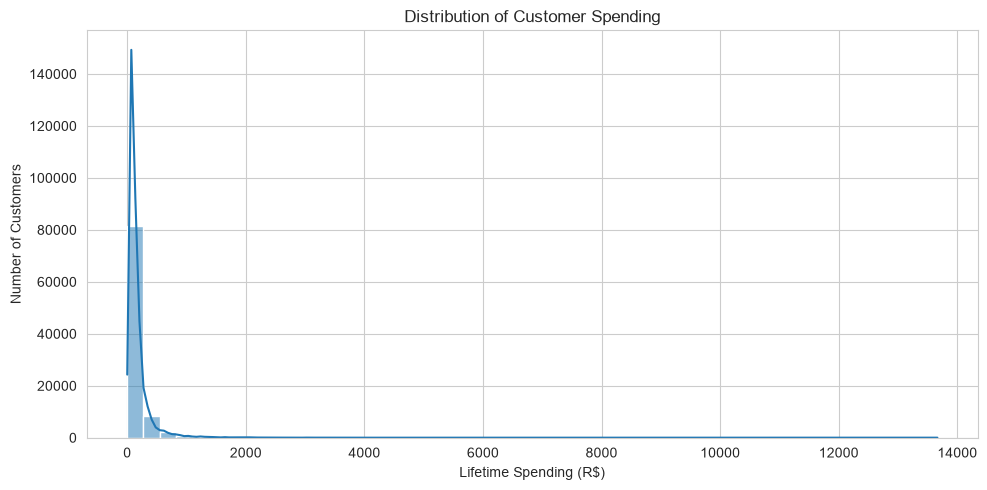

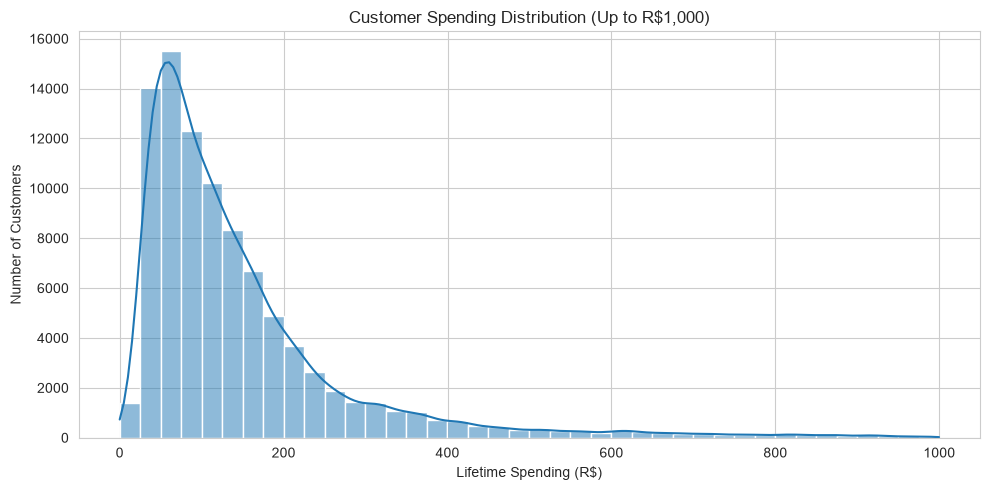

In [33]:
# Step 29: Customer Spending Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_spending,
    x="lifetime_spending",
    bins=50,
    kde=True
)

plt.title("Distribution of Customer Spending")
plt.xlabel("Lifetime Spending (R$)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

# Spending distribution without extreme high values
plt.figure(figsize=(10, 5))

sns.histplot(
    data=customer_spending[
        customer_spending["lifetime_spending"] <= 1000
    ],
    x="lifetime_spending",
    bins=40,
    kde=True
)

plt.title("Customer Spending Distribution (Up to R$1,000)")
plt.xlabel("Lifetime Spending (R$)")
plt.ylabel("Number of Customers")
plt.tight_layout()
plt.show()

In [34]:
# Step 30: Customer Spending Segmentation

# Calculate spending quartiles
q1 = customer_spending["lifetime_spending"].quantile(0.25)
q2 = customer_spending["lifetime_spending"].quantile(0.50)
q3 = customer_spending["lifetime_spending"].quantile(0.75)

# Segment customers
customer_spending["customer_segment"] = pd.cut(
    customer_spending["lifetime_spending"],
    bins=[-float("inf"), q1, q2, q3, float("inf")],
    labels=[
        "Low Value",
        "Medium Value",
        "High Value",
        "Top Value"
    ],
    include_lowest=True
)

# Analyze segments
segment_analysis = (
    customer_spending.groupby(
        "customer_segment",
        observed=False
    )
    .agg(
        customer_count=("customer_unique_id", "count"),
        average_spending=("lifetime_spending", "mean"),
        total_spending=("lifetime_spending", "sum")
    )
)

segment_analysis["customer_percentage"] = (
    segment_analysis["customer_count"] /
    len(customer_spending) * 100
).round(2)

segment_analysis["revenue_percentage"] = (
    segment_analysis["total_spending"] /
    customer_spending["lifetime_spending"].sum() * 100
).round(2)

print("CUSTOMER SPENDING SEGMENTATION")
print(segment_analysis.round(2))

CUSTOMER SPENDING SEGMENTATION
                  customer_count  average_spending  total_spending  \
customer_segment                                                     
Low Value                  23340             43.59      1017438.62   
Medium Value               23341             83.55      1950232.97   
High Value                 23337            140.97      3289911.06   
Top Value                  23340            392.67      9164879.12   

                  customer_percentage  revenue_percentage  
customer_segment                                           
Low Value                        25.0                6.60  
Medium Value                     25.0               12.65  
High Value                       25.0               21.33  
Top Value                        25.0               59.43  


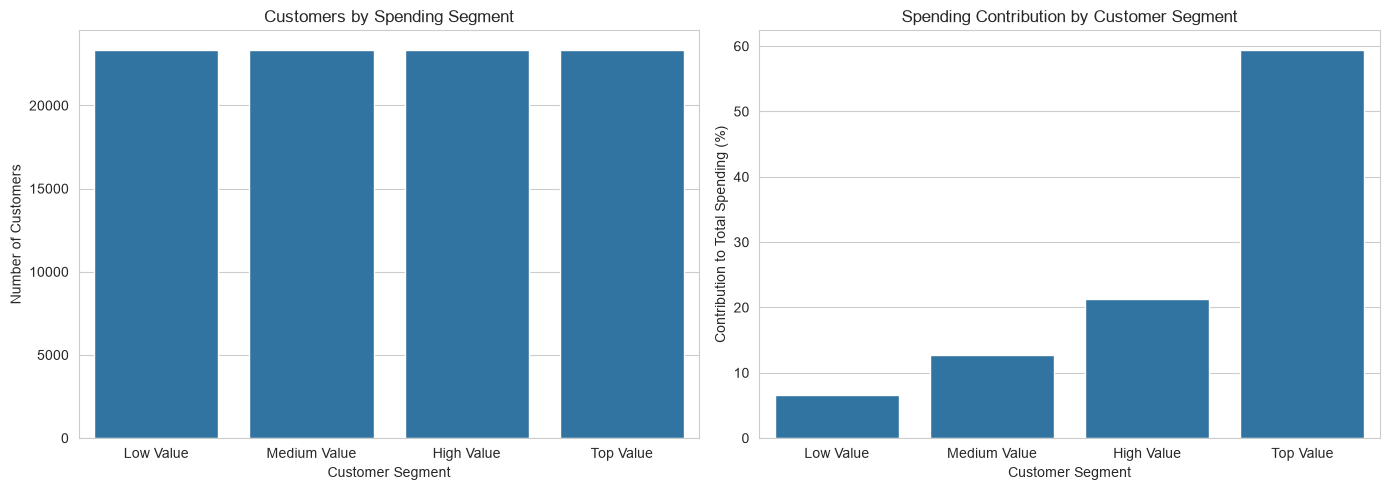

In [35]:
# Step 31: Customer Segment Visualization

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Customer count by segment
sns.barplot(
    data=segment_analysis.reset_index(),
    x="customer_segment",
    y="customer_count",
    ax=axes[0]
)

axes[0].set_title("Customers by Spending Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Number of Customers")

# Spending contribution by segment
sns.barplot(
    data=segment_analysis.reset_index(),
    x="customer_segment",
    y="revenue_percentage",
    ax=axes[1]
)

axes[1].set_title("Spending Contribution by Customer Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Contribution to Total Spending (%)")

plt.tight_layout()
plt.show()


In [36]:
# Step 32: RFM Analysis

# Convert purchase timestamp to datetime
orders["order_purchase_timestamp"] = pd.to_datetime(
    orders["order_purchase_timestamp"],
    errors="coerce"
)

# Get delivered orders with purchase dates
rfm_data = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"].notna())
][["order_id", "customer_id", "order_purchase_timestamp"]].copy()

# Attach unique customer identifiers
rfm_data = rfm_data.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Attach order-level payments
rfm_data = rfm_data.merge(
    order_payments,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Define analysis reference date
reference_date = (
    rfm_data["order_purchase_timestamp"].max()
    + pd.Timedelta(days=1)
)

# Calculate RFM metrics
rfm = (
    rfm_data.groupby("customer_unique_id")
    .agg(
        recency=("order_purchase_timestamp",
                 lambda x: (reference_date - x.max()).days),
        frequency=("order_id", "nunique"),
        monetary=("total_payment", "sum")
    )
    .reset_index()
)

print("RFM ANALYSIS")
print("Total customers:", len(rfm))
print("\nRFM STATISTICS")
print(rfm[["recency", "frequency", "monetary"]].describe().round(2))

print("\nTOP 10 CUSTOMERS BY MONETARY VALUE")
print(
    rfm.sort_values("monetary", ascending=False)
    .head(10)
    .round(2)
    .to_string(index=False)
)

RFM ANALYSIS
Total customers: 93358

RFM STATISTICS
        recency  frequency  monetary
count  93358.00   93358.00  93358.00
mean     237.94       1.03    165.20
std      152.59       0.21    226.31
min        1.00       1.00      0.00
25%      114.00       1.00     63.05
50%      219.00       1.00    107.78
75%      346.00       1.00    182.56
max      714.00      15.00  13664.08

TOP 10 CUSTOMERS BY MONETARY VALUE
              customer_unique_id  recency  frequency  monetary
0a0a92112bd4c708ca5fde585afaa872      334          1  13664.08
da122df9eeddfedc1dc1f5349a1a690c      515          2   7571.63
763c8b1c9c68a0229c42c9fc6f662b93       46          1   7274.88
dc4802a71eae9be1dd28f5d788ceb526      563          1   6929.31
459bef486812aa25204be022145caa62       35          1   6922.21
ff4159b92c40ebe40454e3e6a7c35ed6      462          1   6726.66
4007669dec559734d6f53e029e360987      279          1   6081.54
eebb5dda148d3893cdaf5b5ca3040ccb      498          1   4764.34
48e1ac109dec

In [37]:
# Step 33: RFM Scoring

# Recency: lower is better, so reverse the score
rfm["R_score"] = pd.qcut(
    rfm["recency"].rank(method="first"),
    5,
    labels=[5, 4, 3, 2, 1]
).astype(int)

# Frequency: higher is better
rfm["F_score"] = pd.qcut(
    rfm["frequency"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Monetary: higher is better
rfm["M_score"] = pd.qcut(
    rfm["monetary"].rank(method="first"),
    5,
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Combined RFM score
rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

print("RFM SCORES")
print(rfm[["R_score", "F_score", "M_score"]].describe().round(2))

print("\nRFM SCORE DISTRIBUTION")
print(rfm["RFM_score"].value_counts().head(15))

print("\nSAMPLE CUSTOMER RFM SCORES")
print(rfm.head(10).to_string(index=False))

RFM SCORES
        R_score   F_score   M_score
count  93358.00  93358.00  93358.00
mean       3.00      3.00      3.00
std        1.41      1.41      1.41
min        1.00      1.00      1.00
25%        2.00      2.00      2.00
50%        3.00      3.00      3.00
75%        4.00      4.00      4.00
max        5.00      5.00      5.00

RFM SCORE DISTRIBUTION
RFM_score
555    997
455    952
255    910
355    884
222    859
242    853
155    852
424    837
531    836
131    829
331    823
344    818
454    815
142    807
112    806
Name: count, dtype: int64

SAMPLE CUSTOMER RFM SCORES
              customer_unique_id  recency  frequency  monetary  R_score  F_score  M_score RFM_score
0000366f3b9a7992bf8c76cfdf3221e2      112          1    141.90        4        1        4       414
0000b849f77a49e4a4ce2b2a4ca5be3f      115          1     27.19        4        1        1       411
0000f46a3911fa3c0805444483337064      537          1     86.22        1        1        2       112
0000f6ccb074

In [38]:
# Step 34: Business-Friendly RFM Segmentation

def segment_customer(row):

    if row["R_score"] >= 4 and row["F_score"] >= 4:
        return "Champions"

    elif row["F_score"] >= 4:
        return "Loyal Customers"

    elif row["R_score"] >= 4:
        return "Recent Customers"

    elif row["R_score"] <= 2 and row["F_score"] >= 3:
        return "At Risk"

    else:
        return "Others"


rfm["customer_segment"] = rfm.apply(
    segment_customer,
    axis=1
)

# Segment summary
rfm_segment_analysis = (
    rfm.groupby("customer_segment")
    .agg(
        customer_count=("customer_unique_id", "count"),
        average_spending=("monetary", "mean"),
        average_frequency=("frequency", "mean"),
        average_recency=("recency", "mean")
    )
    .sort_values("customer_count", ascending=False)
)

rfm_segment_analysis["customer_percentage"] = (
    rfm_segment_analysis["customer_count"] /
    len(rfm) * 100
).round(2)

print("RFM CUSTOMER SEGMENTATION")
print(rfm_segment_analysis.round(2))

RFM CUSTOMER SEGMENTATION
                  customer_count  average_spending  average_frequency  \
customer_segment                                                        
Others                     26105            158.36               1.00   
Recent Customers           22472            164.43               1.00   
Loyal Customers            22472            167.31               1.08   
Champions                  14871            176.97               1.09   
At Risk                     7438            161.58               1.00   

                  average_recency  customer_percentage  
customer_segment                                        
Others                     320.80                27.96  
Recent Customers            90.80                24.07  
Loyal Customers            335.29                24.07  
Champions                   89.71                15.93  
At Risk                    393.93                 7.97  


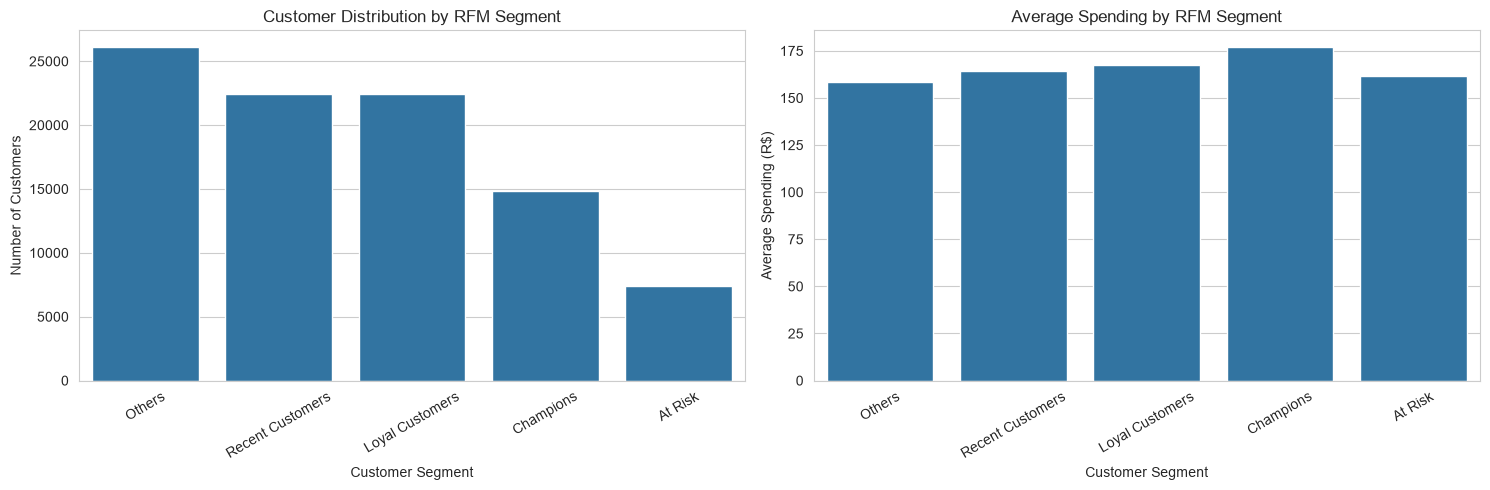

In [39]:
# Step 35: RFM Segment Visualization

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Customer distribution
sns.barplot(
    data=rfm_segment_analysis.reset_index(),
    x="customer_segment",
    y="customer_count",
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by RFM Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=30)

# Average spending
sns.barplot(
    data=rfm_segment_analysis.reset_index(),
    x="customer_segment",
    y="average_spending",
    ax=axes[1]
)

axes[1].set_title("Average Spending by RFM Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Average Spending (R$)")
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

In [40]:
# Step 36: Improved RFM Frequency Scoring

rfm["F_score"] = pd.cut(
    rfm["frequency"],
    bins=[0, 1, 2, 4, 9, float("inf")],
    labels=[1, 2, 3, 4, 5]
).astype(int)

# Recalculate combined RFM score
rfm["RFM_score"] = (
    rfm["R_score"].astype(str) +
    rfm["F_score"].astype(str) +
    rfm["M_score"].astype(str)
)

print("IMPROVED FREQUENCY SCORE DISTRIBUTION")
print(rfm["F_score"].value_counts().sort_index())

print("\nACTUAL ORDER FREQUENCY BY SCORE")
print(
    rfm.groupby("F_score", observed=False)["frequency"]
    .agg(["count", "min", "max", "mean"])
)

print("\nUPDATED RFM SCORE DISTRIBUTION")
print(rfm["RFM_score"].value_counts().head(15))

IMPROVED FREQUENCY SCORE DISTRIBUTION
F_score
1    90557
2     2573
3      209
4       18
5        1
Name: count, dtype: int64

ACTUAL ORDER FREQUENCY BY SCORE
         count  min  max       mean
F_score                            
1        90557    1    1   1.000000
2         2573    2    2   2.000000
3          209    3    4   3.133971
4           18    5    9   5.833333
5            1   15   15  15.000000

UPDATED RFM SCORE DISTRIBUTION
RFM_score
212    3986
112    3910
311    3892
111    3889
414    3754
413    3736
514    3721
314    3700
511    3696
513    3690
313    3643
113    3637
312    3618
411    3606
213    3585
Name: count, dtype: int64


In [41]:
# Step 37: Updated RFM Customer Segmentation

def improved_segment_customer(row):

    if row["R_score"] >= 4 and row["F_score"] >= 4:
        return "Champions"

    elif row["F_score"] >= 3:
        return "Loyal Customers"

    elif row["R_score"] >= 4 and row["F_score"] == 1:
        return "Recent One-Time Customers"

    elif row["R_score"] <= 2 and row["F_score"] >= 2:
        return "At Risk"

    else:
        return "Others"


rfm["customer_segment"] = rfm.apply(
    improved_segment_customer,
    axis=1
)

# Calculate updated segment metrics
improved_rfm_segments = (
    rfm.groupby("customer_segment")
    .agg(
        customer_count=("customer_unique_id", "count"),
        average_spending=("monetary", "mean"),
        average_frequency=("frequency", "mean"),
        average_recency=("recency", "mean")
    )
    .sort_values("customer_count", ascending=False)
)

improved_rfm_segments["customer_percentage"] = (
    improved_rfm_segments["customer_count"] /
    len(rfm) * 100
).round(2)

print("IMPROVED RFM CUSTOMER SEGMENTATION")
print(improved_rfm_segments.round(2))

IMPROVED RFM CUSTOMER SEGMENTATION
                           customer_count  average_spending  \
customer_segment                                              
Others                              56070            162.41   
Recent One-Time Customers           36135            164.33   
At Risk                               925            284.07   
Loyal Customers                       214            487.15   
Champions                              14            807.12   

                           average_frequency  average_recency  \
customer_segment                                                
Others                                  1.03           330.81   
Recent One-Time Customers               1.00            90.41   
At Risk                                 2.00           380.78   
Loyal Customers                         3.21           209.29   
Champions                               6.21            95.07   

                           customer_percentage  
customer_segment  

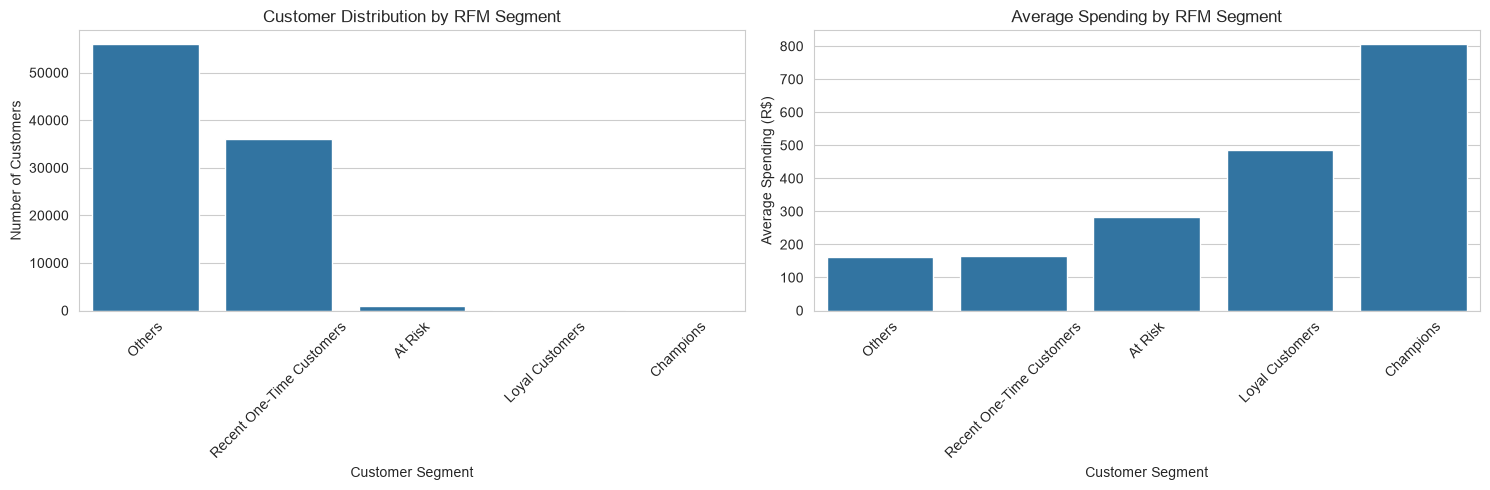

In [42]:
# Step 38: Improved RFM Segment Visualization

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Customer distribution
sns.barplot(
    data=improved_rfm_segments.reset_index(),
    x="customer_segment",
    y="customer_count",
    ax=axes[0]
)

axes[0].set_title("Customer Distribution by RFM Segment")
axes[0].set_xlabel("Customer Segment")
axes[0].set_ylabel("Number of Customers")
axes[0].tick_params(axis="x", rotation=45)

# Average spending
sns.barplot(
    data=improved_rfm_segments.reset_index(),
    x="customer_segment",
    y="average_spending",
    ax=axes[1]
)

axes[1].set_title("Average Spending by RFM Segment")
axes[1].set_xlabel("Customer Segment")
axes[1].set_ylabel("Average Spending (R$)")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [43]:
# Step 39: Geographical Sales Analysis

# Select delivered orders
geo_data = orders[
    orders["order_status"] == "delivered"
][["order_id", "customer_id"]].copy()

# Attach customer state
geo_data = geo_data.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Attach order-level payment values
geo_data = geo_data.merge(
    order_payments,
    on="order_id",
    how="left",
    validate="one_to_one"
)

# Aggregate by customer state
state_analysis = (
    geo_data.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        unique_customers=("customer_id", "nunique"),
        total_payment=("total_payment", "sum"),
        average_payment=("total_payment", "mean")
    )
    .sort_values("total_orders", ascending=False)
)

print("GEOGRAPHICAL SALES ANALYSIS")
print("Total states:", len(state_analysis))

print("\nTOP 10 STATES BY DELIVERED ORDERS")
print(state_analysis.head(10).round(2))

print("\nTOP 10 STATES BY PAYMENT VALUE")
print(
    state_analysis.sort_values(
        "total_payment", ascending=False
    ).head(10).round(2)
)

print("\nTOTAL RECORDED PAYMENT VALUE:")
print("R$", round(state_analysis["total_payment"].sum(), 2))

GEOGRAPHICAL SALES ANALYSIS
Total states: 27

TOP 10 STATES BY DELIVERED ORDERS
                total_orders  unique_customers  total_payment  average_payment
customer_state                                                                
SP                     40501             40501     5770266.19           142.48
RJ                     12350             12350     2055690.45           166.45
MG                     11354             11354     1819277.61           160.23
RS                      5345              5345      861802.40           161.24
PR                      4923              4923      781919.55           158.83
SC                      3546              3546      595208.40           167.85
BA                      3256              3256      591270.60           181.59
DF                      2080              2080      346146.17           166.42
ES                      1995              1995      317682.65           159.24
GO                      1957              1957     

In [44]:
# Step 40: Correct Geographical Customer Analysis

# Add stable customer identifiers
geo_data = geo_data.merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Recalculate state metrics
state_analysis = (
    geo_data.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        unique_customers=("customer_unique_id", "nunique"),
        total_payment=("total_payment", "sum")
    )
    .sort_values("total_payment", ascending=False)
)

# Calculate percentage contribution
total_payment = state_analysis["total_payment"].sum()

state_analysis["payment_percentage"] = (
    state_analysis["total_payment"] / total_payment * 100
).round(2)

state_analysis["order_percentage"] = (
    state_analysis["total_orders"] /
    state_analysis["total_orders"].sum() * 100
).round(2)

print("CORRECTED STATE ANALYSIS")
print(state_analysis.head(10).round(2))

print("\nTOP STATE PAYMENT SHARE:")
print(state_analysis["payment_percentage"].head(5))

CORRECTED STATE ANALYSIS
                total_orders  unique_customers  total_payment  \
customer_state                                                  
SP                     40501             39156     5770266.19   
RJ                     12350             11917     2055690.45   
MG                     11354             11001     1819277.61   
RS                      5345              5168      861802.40   
PR                      4923              4769      781919.55   
SC                      3546              3449      595208.40   
BA                      3256              3158      591270.60   
DF                      2080              2019      346146.17   
GO                      1957              1895      334294.22   
ES                      1995              1928      317682.65   

                payment_percentage  order_percentage  
customer_state                                        
SP                           37.41             41.98  
RJ                           

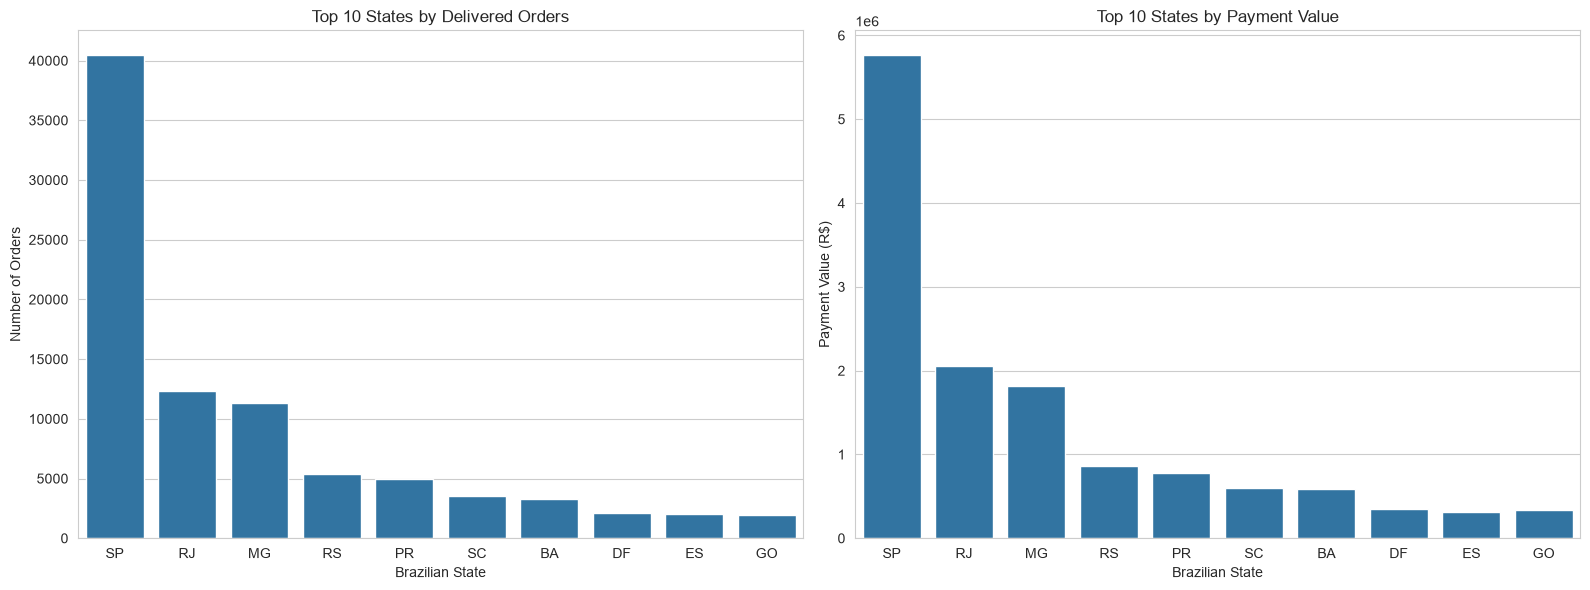

In [45]:
# Step 41: State-Level Performance Visualization

top_states = (
    state_analysis
    .sort_values("total_orders", ascending=False)
    .head(10)
    .reset_index()
)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Delivered orders by state
sns.barplot(
    data=top_states,
    x="customer_state",
    y="total_orders",
    ax=axes[0]
)

axes[0].set_title("Top 10 States by Delivered Orders")
axes[0].set_xlabel("Brazilian State")
axes[0].set_ylabel("Number of Orders")

# Payment value by state
sns.barplot(
    data=top_states,
    x="customer_state",
    y="total_payment",
    ax=axes[1]
)

axes[1].set_title("Top 10 States by Payment Value")
axes[1].set_xlabel("Brazilian State")
axes[1].set_ylabel("Payment Value (R$)")

plt.tight_layout()
plt.show()

TOP 10 STATES BY AVERAGE PAYMENT
customer_state  total_orders  average_payment
            PB           517           266.60
            AC            80           244.83
            AP            67           240.92
            AL           397           237.27
            RO           243           234.47
            PA           946           224.13
            PI           476           221.16
            RR            41           220.48
            TO           274           219.00
            RN           474           212.51

BOTTOM 10 STATES BY AVERAGE PAYMENT
customer_state  total_orders  average_payment
            BA          3256           181.59
            GO          1957           170.82
            SC          3546           167.85
            RJ         12350           166.45
            DF          2080           166.42
            RS          5345           161.24
            MG         11354           160.23
            ES          1995           159.24
          

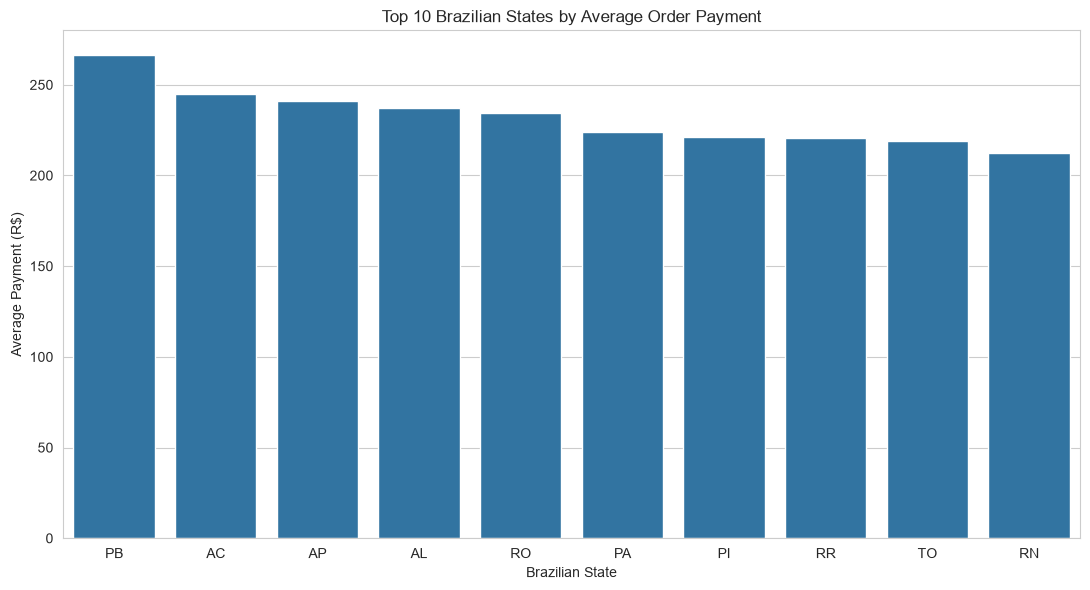

In [46]:
# Step 42: Average Payment by Brazilian State

state_average_payment = (
    geo_data.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        average_payment=("total_payment", "mean")
    )
    .sort_values("average_payment", ascending=False)
    .reset_index()
)

print("TOP 10 STATES BY AVERAGE PAYMENT")
print(state_average_payment.head(10).round(2).to_string(index=False))

print("\nBOTTOM 10 STATES BY AVERAGE PAYMENT")
print(state_average_payment.tail(10).round(2).to_string(index=False))

# Visualize top 10 states
plt.figure(figsize=(11, 6))

sns.barplot(
    data=state_average_payment.head(10),
    x="customer_state",
    y="average_payment"
)

plt.title("Top 10 Brazilian States by Average Order Payment")
plt.xlabel("Brazilian State")
plt.ylabel("Average Payment (R$)")
plt.tight_layout()
plt.show()

In [47]:
# Step 43: Delivery Performance by State

# Attach delivery information to geographical data
state_delivery_data = geo_data.merge(
    delivered_orders[
        ["order_id", "delivery_days", "delivery_performance"]
    ],
    on="order_id",
    how="inner",
    validate="one_to_one"
)

# Calculate state-level delivery performance
state_delivery_analysis = (
    state_delivery_data.groupby("customer_state")
    .agg(
        total_orders=("order_id", "nunique"),
        late_orders=(
            "delivery_performance",
            lambda x: (x == "Late").sum()
        ),
        average_delivery_days=("delivery_days", "mean")
    )
)

state_delivery_analysis["late_delivery_percentage"] = (
    state_delivery_analysis["late_orders"] /
    state_delivery_analysis["total_orders"] * 100
).round(2)

state_delivery_analysis = state_delivery_analysis.sort_values(
    "late_delivery_percentage",
    ascending=False
)

print("TOP 10 STATES BY LATE DELIVERY PERCENTAGE")
print(state_delivery_analysis.head(10).round(2))

print("\nBOTTOM 10 STATES BY LATE DELIVERY PERCENTAGE")
print(state_delivery_analysis.tail(10).round(2))

TOP 10 STATES BY LATE DELIVERY PERCENTAGE
                total_orders  late_orders  average_delivery_days  \
customer_state                                                     
AL                       397           85                  24.54   
MA                       717          125                  21.57   
SE                       335           51                  21.52   
PI                       476           66                  19.46   
CE                      1279          176                  21.27   
RR                        41            5                  29.39   
BA                      3256          396                  19.34   
RJ                     12350         1495                  15.31   
PA                       946          106                  23.77   
ES                      1995          214                  15.79   

                late_delivery_percentage  
customer_state                            
AL                                 21.41  
MA          

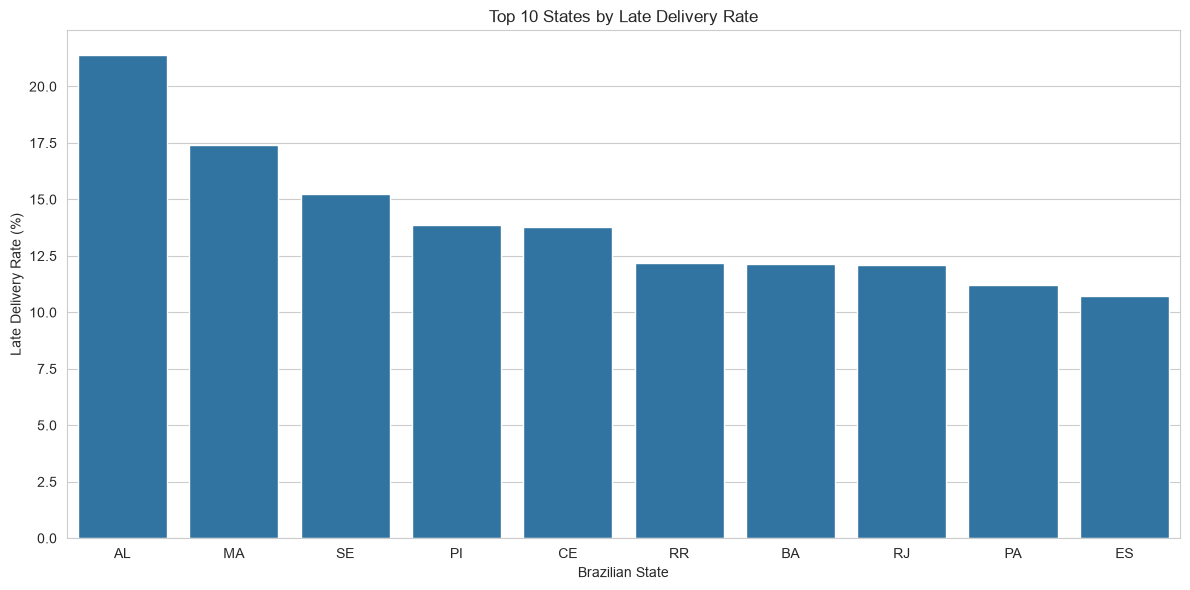

In [48]:
# Step 44: Late Delivery Rate by State

top_late_states = (
    state_delivery_analysis
    .sort_values("late_delivery_percentage", ascending=False)
    .head(10)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=top_late_states,
    x="customer_state",
    y="late_delivery_percentage"
)

plt.title("Top 10 States by Late Delivery Rate")
plt.xlabel("Brazilian State")
plt.ylabel("Late Delivery Rate (%)")

plt.tight_layout()
plt.show()

In [49]:
# Step 45: Customer Satisfaction by State

# Attach unique customer identifiers and state to reviews
state_review_data = reviews.merge(
    orders[["order_id", "customer_id", "order_status"]],
    on="order_id",
    how="inner",
    validate="many_to_one"
)

state_review_data = state_review_data[
    state_review_data["order_status"] == "delivered"
].copy()

state_review_data = state_review_data.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left",
    validate="many_to_one"
)

# Average multiple reviews belonging to the same order
order_state_reviews = (
    state_review_data.groupby(
        ["order_id", "customer_state"]
    )
    .agg(
        average_review_score=("review_score", "mean")
    )
    .reset_index()
)

# Calculate state-level satisfaction
state_satisfaction = (
    order_state_reviews.groupby("customer_state")
    .agg(
        reviewed_orders=("order_id", "nunique"),
        average_review_score=("average_review_score", "mean")
    )
    .sort_values("average_review_score")
)

print("10 STATES WITH LOWEST CUSTOMER RATINGS")
print(state_satisfaction.head(10).round(2))

print("\n10 STATES WITH HIGHEST CUSTOMER RATINGS")
print(state_satisfaction.tail(10).sort_values(
    "average_review_score",
    ascending=False
).round(2))

10 STATES WITH LOWEST CUSTOMER RATINGS
                reviewed_orders  average_review_score
customer_state                                       
MA                          712                  3.83
AL                          394                  3.85
RR                           41                  3.90
SE                          334                  3.91
PA                          933                  3.91
BA                         3229                  3.93
CE                         1273                  3.94
RJ                        12211                  3.97
PI                          471                  3.99
PB                          512                  4.08

10 STATES WITH HIGHEST CUSTOMER RATINGS
                reviewed_orders  average_review_score
customer_state                                       
SP                        40273                  4.25
AM                          144                  4.24
AP                           66                  4.24
PR

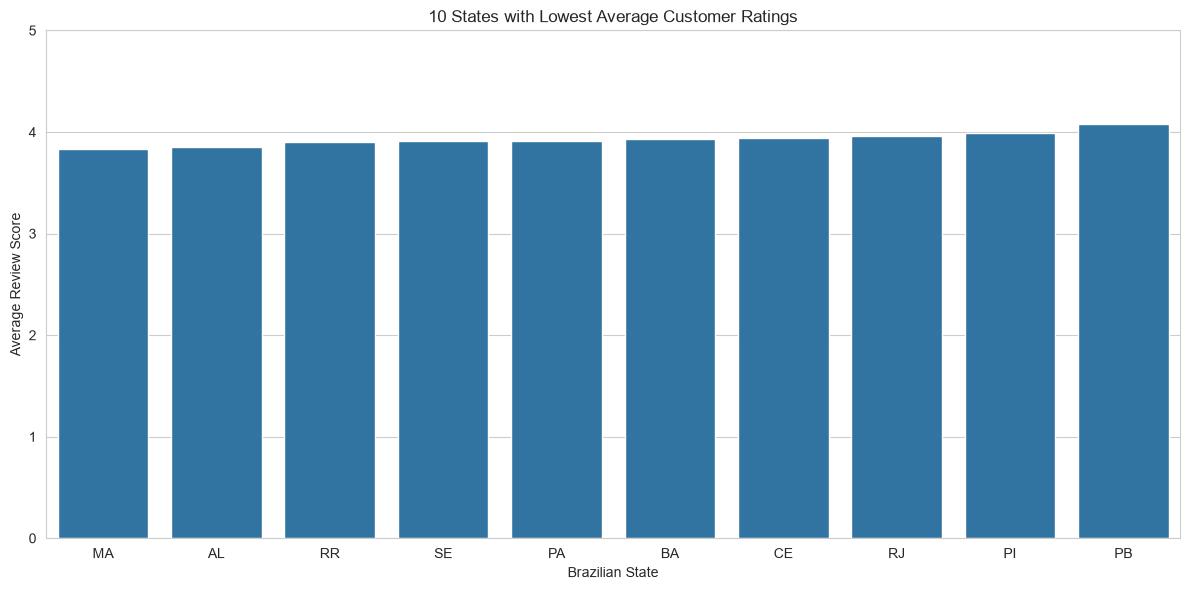

In [50]:
# Step 46: Customer Satisfaction Visualization

# Lowest-rated states
lowest_rated_states = (
    state_satisfaction
    .head(10)
    .reset_index()
    .sort_values("average_review_score")
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=lowest_rated_states,
    x="customer_state",
    y="average_review_score"
)

plt.title("10 States with Lowest Average Customer Ratings")
plt.xlabel("Brazilian State")
plt.ylabel("Average Review Score")
plt.ylim(0, 5)

plt.tight_layout()
plt.show()

DELIVERY PERFORMANCE VS CUSTOMER SATISFACTION
                total_orders  late_delivery_percentage  average_delivery_days  \
customer_state                                                                  
AL                       397                     21.41                  24.54   
MA                       717                     17.43                  21.57   
SE                       335                     15.22                  21.52   
PI                       476                     13.87                  19.46   
CE                      1279                     13.76                  21.27   
RR                        41                     12.20                  29.39   
BA                      3256                     12.16                  19.34   
RJ                     12350                     12.11                  15.31   
PA                       946                     11.21                  23.77   
ES                      1995                     10.73         

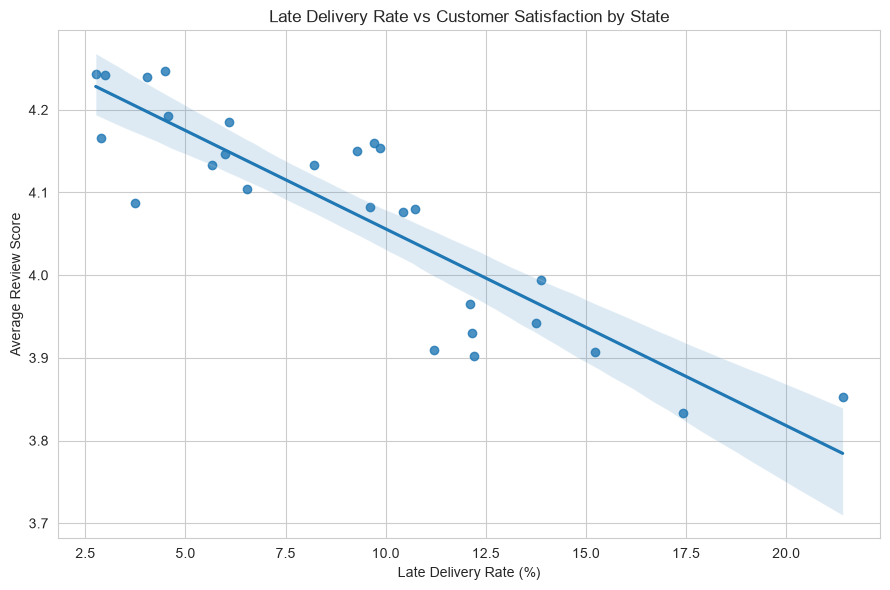

In [51]:
# Step 47: Delivery Performance vs Customer Satisfaction

# Combine state delivery and satisfaction metrics
state_delivery_satisfaction = state_delivery_analysis[
    ["total_orders", "late_delivery_percentage", "average_delivery_days"]
].join(
    state_satisfaction[["average_review_score"]],
    how="inner"
)

print("DELIVERY PERFORMANCE VS CUSTOMER SATISFACTION")
print(
    state_delivery_satisfaction
    .sort_values("late_delivery_percentage", ascending=False)
    .round(2)
)

# Calculate correlation
correlation = state_delivery_satisfaction[
    ["late_delivery_percentage", "average_review_score"]
].corr().iloc[0, 1]

print("\nCORRELATION BETWEEN LATE DELIVERY RATE AND CUSTOMER RATING:")
print(round(correlation, 3))

# Scatter plot
plt.figure(figsize=(9, 6))

sns.regplot(
    data=state_delivery_satisfaction,
    x="late_delivery_percentage",
    y="average_review_score"
)

plt.title("Late Delivery Rate vs Customer Satisfaction by State")
plt.xlabel("Late Delivery Rate (%)")
plt.ylabel("Average Review Score")

plt.tight_layout()
plt.show()

In [52]:
# Step 48: Key Business Insights

print("=" * 60)
print("SMARTCOMMERCE - KEY BUSINESS INSIGHTS")
print("=" * 60)

print("\n1. CUSTOMER RETENTION")
print(f"Repeat customer rate: {repeat_percentage:.2f}%")

print("\n2. ORDER DELIVERY")
print(f"On-time or early delivery: {(delivered_orders['delivery_performance'] == 'On Time or Early').mean() * 100:.2f}%")
print(f"Late delivery: {(delivered_orders['delivery_performance'] == 'Late').mean() * 100:.2f}%")
print(f"Average delivery time: {delivered_orders['delivery_days'].mean():.2f} days")

print("\n3. CUSTOMER SATISFACTION")
print(f"Average review score: {reviews['review_score'].mean():.2f}/5")

print("\n4. PRODUCT SALES")
print(f"Total delivered product sales: R${category_sales['price'].sum():,.2f}")

print("\n5. CUSTOMER SPENDING")
print(f"Average customer spending: R${customer_spending['total_spending'].mean():,.2f}")

print("\n6. GEOGRAPHICAL PERFORMANCE")
print(f"Top state by payment value: {state_analysis['total_payment'].idxmax()}")
print(f"Top state's payment share: {state_analysis['payment_percentage'].max():.2f}%")

print("\n7. DELIVERY AND SATISFACTION")
print(f"State-level correlation: {correlation:.3f}")

print("\n" + "=" * 60)

SMARTCOMMERCE - KEY BUSINESS INSIGHTS

1. CUSTOMER RETENTION
Repeat customer rate: 3.00%

2. ORDER DELIVERY
On-time or early delivery: 93.23%
Late delivery: 6.77%
Average delivery time: 12.56 days

3. CUSTOMER SATISFACTION
Average review score: 4.09/5

4. PRODUCT SALES
Total delivered product sales: R$13,221,498.11

5. CUSTOMER SPENDING


KeyError: 'total_spending'

In [53]:
print("Customer spending columns:")
print(customer_spending.columns.tolist())

print("\nFirst 5 rows:")
display(customer_spending.head())

Customer spending columns:
['customer_unique_id', 'total_orders', 'lifetime_spending', 'customer_segment']

First 5 rows:


,customer_unique_id,total_orders,lifetime_spending,customer_segment
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,High Value
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,Low Value
2,0000f46a3911fa3c0805444483337064,1,86.22,Medium Value
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,Low Value
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,Top Value


In [54]:
# Step 48: Key Business Insights

print("=" * 60)
print("SMARTCOMMERCE - KEY BUSINESS INSIGHTS")
print("=" * 60)

print("\n1. CUSTOMER RETENTION")
print(f"Repeat customer rate: {repeat_percentage:.2f}%")

print("\n2. ORDER DELIVERY")
print(f"On-time or early delivery: {(delivered_orders['delivery_performance'] == 'On Time or Early').mean() * 100:.2f}%")
print(f"Late delivery: {(delivered_orders['delivery_performance'] == 'Late').mean() * 100:.2f}%")
print(f"Average delivery time: {delivered_orders['delivery_days'].mean():.2f} days")

print("\n3. CUSTOMER SATISFACTION")
print(f"Average review score: {reviews['review_score'].mean():.2f}/5")

print("\n4. PRODUCT SALES")
print(f"Total delivered product sales: R${category_sales['price'].sum():,.2f}")

print("\n5. CUSTOMER SPENDING")
print(f"Average customer spending: R${customer_spending['lifetime_spending'].mean():,.2f}")

print("\n6. GEOGRAPHICAL PERFORMANCE")
print(f"Top state by payment value: {state_analysis['total_payment'].idxmax()}")
print(f"Top state's payment share: {state_analysis['payment_percentage'].max():.2f}%")

print("\n7. DELIVERY AND SATISFACTION")
print(f"State-level correlation: {correlation:.3f}")

print("\n" + "=" * 60)

SMARTCOMMERCE - KEY BUSINESS INSIGHTS

1. CUSTOMER RETENTION
Repeat customer rate: 3.00%

2. ORDER DELIVERY
On-time or early delivery: 93.23%
Late delivery: 6.77%
Average delivery time: 12.56 days

3. CUSTOMER SATISFACTION
Average review score: 4.09/5

4. PRODUCT SALES
Total delivered product sales: R$13,221,498.11

5. CUSTOMER SPENDING
Average customer spending: R$165.20

6. GEOGRAPHICAL PERFORMANCE
Top state by payment value: SP
Top state's payment share: 37.41%

7. DELIVERY AND SATISFACTION
State-level correlation: -0.883

